# Topic 1: Normal Distribution

## Step 1: Understand the Concept

A normal distribution is a probability distribution in which most values are concentrated around the mean, while fewer values appear toward both ends.

It is also called a bell-shaped distribution because its graph looks like a bell.

### Why Is It Important?

Normal distribution helps us understand how numerical values are spread around their average. It is useful in statistical analysis, probability, and some machine learning techniques.

## Step 2: Demonstrate the Concept

### Simple Example

Consider students' exam marks. If most students score near the average and fewer students score very low or very high marks, the distribution may look approximately bell-shaped.

### Real-World Example

Human heights within a suitable population may approximately follow a normal distribution.

### Business Example

A business can analyze product measurements to understand whether most products are close to the target measurement.

### AI/ML Use Case

Normal distribution is useful in statistical modeling and in understanding errors in certain machine learning models.

### Important Characteristics

- The distribution is approximately bell-shaped.
- It is symmetric around the mean.
- In an ideal normal distribution, the mean, median, and mode are equal.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "online_retail_II.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (525461, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


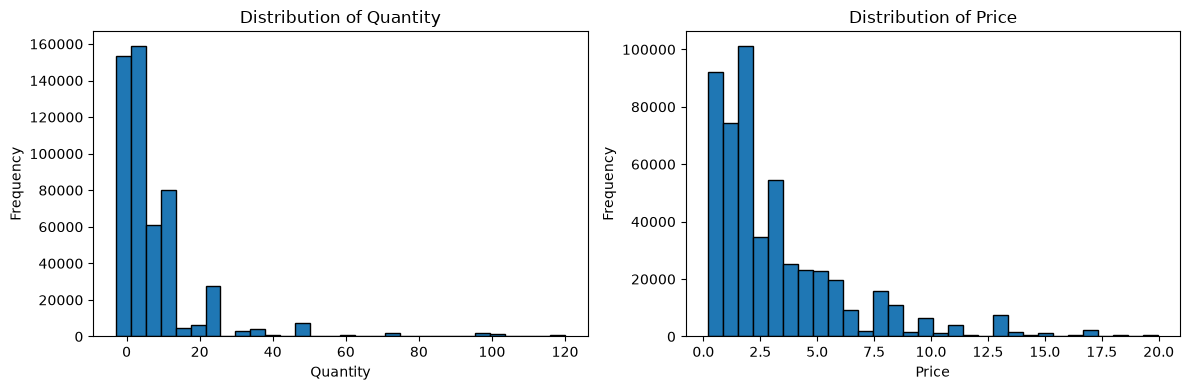

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Select numerical features
features = ["Quantity", "Price"]

# Plot the distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, feature in zip(axes, features):
    values = pd.to_numeric(df[feature], errors="coerce").dropna()

    # Limit extreme values for clearer visualization
    lower = values.quantile(0.01)
    upper = values.quantile(0.99)
    values = values[(values >= lower) & (values <= upper)]

    ax.hist(values, bins=30, edgecolor="black")
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## Step 3: Code Explanation

- `features` selects the numerical columns to analyze.
- `pd.to_numeric()` converts values into numeric format.
- `errors="coerce"` converts invalid values into missing values.
- `dropna()` removes missing values.
- `quantile(0.01)` and `quantile(0.99)` identify the 1st and 99th percentiles.
- Filtering between these percentiles reduces the influence of extreme values on the visualization. It does not permanently remove rows from the dataset.
- `plt.hist()` displays the frequency distribution of each feature.
- `plt.tight_layout()` arranges the charts neatly.

### How to Interpret the Output

Check whether each histogram is bell-shaped and symmetric or has a long tail on one side.

Retail data may be skewed rather than normally distributed. Write your observations based on the actual charts instead of assuming the data is normal.

### Where It Is Used in AI/ML or Data Analytics

Distribution analysis helps analysts understand numerical features, detect unusual patterns, and decide whether transformations or statistical methods may be appropriate.

# Topic 2: Uniform Distribution

## Step 1: Understand the Concept

A uniform distribution is a probability distribution in which all possible outcomes have equal probability in a discrete distribution, or equal probability density across equal-width intervals in a continuous distribution.

In a continuous uniform distribution, values are spread evenly between a minimum and maximum limit.

### Why Is It Important?

Uniform distribution helps us understand evenly spread data and provides a useful comparison with other distribution shapes. It is also used in simulations and random data generation.

## Step 2: Demonstrate the Concept

### Simple Example

Imagine a fair random number generator that produces values uniformly between 0 and 10. Values across equal-width intervals have approximately equal chances of occurring.

### Real-World Example

A computer simulation may generate random values uniformly within a specified range to test different scenarios.

### Business Example

A business may use uniform random sampling to select random records from a defined range for testing or simulation.

### AI/ML Use Case

Uniform random values can be used to initialize some model parameters, generate synthetic inputs, and support simulation experiments.

### Important Characteristics

- A continuous uniform distribution has a constant probability density between its limits.
- Its histogram may look approximately flat when enough samples are generated.
- Random samples will not have exactly equal frequencies in every interval.
- Real-world business data does not automatically follow a uniform distribution.

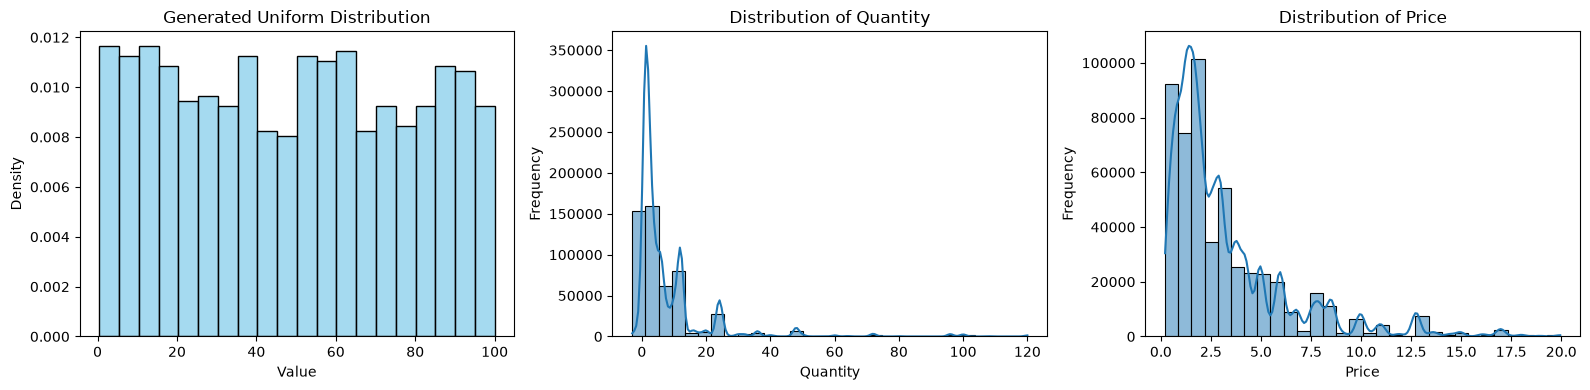


Feature: Quantity
Valid observations: 525461
Minimum: -9600
Maximum: 19152
Mean: 10.34
Median: 3.0
Standard deviation: 107.42
Skewness: 36.04

Feature: Price
Valid observations: 525461
Minimum: -53594.36
Maximum: 25111.09
Mean: 4.69
Median: 2.1
Standard deviation: 146.13
Skewness: -140.77


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical features
features = ["Quantity", "Price"]

distribution_data = df[features].copy()

# Convert selected columns to numeric
for feature in features:
    distribution_data[feature] = pd.to_numeric(
        distribution_data[feature], errors="coerce"
    )

# Generate reference uniform data for comparison
np.random.seed(42)
uniform_data = np.random.uniform(
    low=0, high=100, size=1000
)

# Plot uniform reference data and real dataset features
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(
    uniform_data, bins=20, stat="density",
    ax=axes[0], color="skyblue"
)
axes[0].set_title("Generated Uniform Distribution")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Density")

for ax, feature in zip(axes[1:], features):
    values = distribution_data[feature].dropna()

    # Limit extreme values for visualization only
    lower = values.quantile(0.01)
    upper = values.quantile(0.99)
    plot_values = values[
        (values >= lower) & (values <= upper)
    ]

    sns.histplot(
        plot_values, bins=30, ax=ax, kde=True
    )
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# Summary statistics and skewness
for feature in features:
    values = distribution_data[feature].dropna()

    print(f"\nFeature: {feature}")
    print("Valid observations:", len(values))
    print("Minimum:", values.min())
    print("Maximum:", values.max())
    print("Mean:", round(values.mean(), 2))
    print("Median:", round(values.median(), 2))
    print("Standard deviation:", round(values.std(), 2))
    print("Skewness:", round(values.skew(), 2))


## Step 3: Code Explanation and Analysis

### 1. What the Code Does

- Selects the `Quantity` and `Price` columns from the retail dataset.
- Converts their values to numeric format and excludes missing values from the analysis.
- Generates 1,000 random values from a uniform distribution between 0 and 100.
- Plots the generated uniform data alongside the real dataset distributions.
- Calculates minimum, maximum, mean, median, standard deviation, and skewness.

### 2. Why These Methods Were Used

- **Pandas:** Selects columns and prepares numerical data.
- **NumPy:** Generates uniform random values and supports numerical calculations.
- **Matplotlib:** Arranges and displays multiple plots.
- **Seaborn:** Creates histograms and KDE curves to compare distribution shapes.
- **Mean and Median:** Describe the center of the data.
- **Standard Deviation:** Describes the spread.
- **Skewness:** Helps identify asymmetry.

The generated uniform data acts as a reference example. It does not mean the retail data should also be uniform.

### 3. What the Output Means

- **Generated Uniform Distribution:** Its histogram should look approximately flat, although random variation may cause differences between bins.
- **Quantity Histogram:** Shows how frequently different quantities occur.
- **Price Histogram:** Shows how frequently different prices occur.
- **Minimum and Maximum:** Show the observed range.
- **Mean and Median:** Help describe the center.
- **Standard Deviation:** Helps describe the spread.
- **Skewness:** Indicates whether the distribution leans toward the left or right.

### 4. Insights That Can Be Obtained

After running the code, check:

- Whether the generated uniform data appears approximately flat.
- Whether `Quantity` and `Price` are evenly distributed or concentrated in particular ranges.
- Whether the mean and median differ noticeably.
- Whether the features show signs of skewness.
- Whether extreme observations may influence the distribution.

Record findings based on the actual output rather than assuming a particular result.

### 5. How the Result Can Affect an ML Pipeline

- **Preprocessing:** A skewed feature may require a transformation for some models.
- **Feature Scaling:** Uniform distribution does not automatically mean that a feature is properly scaled for every algorithm.
- **Data Generation:** Uniform sampling can help create test inputs and simulation data.
- **Model Selection:** Understanding distributions helps check assumptions made by statistical models.
- **Data Quality:** Unusual concentrations or unexpected gaps may need further investigation.

### Important Note

The 1st-to-99th-percentile filter is used only for plotting the retail features. Summary statistics use all valid values. The original dataset is not modified.

# Topic 3: Skewness

## Step 1: Understand the Concept

Skewness is a statistical measure that describes the asymmetry of a data distribution.

It helps us understand whether a distribution is balanced or has a longer tail on one side.

### Types of Skewness

- **Zero or Near-Zero Skewness:** The distribution has little or no asymmetry.
- **Positive Skewness:** The distribution has a longer tail toward the right.
- **Negative Skewness:** The distribution has a longer tail toward the left.

### Why Is It Important?

Skewness helps identify unusual distribution patterns, understand the relationship between the mean and median, and decide whether additional data preprocessing may be useful.

## Step 2: Demonstrate the Concept

### Simple Example

Consider monthly spending.

If most people spend moderate amounts and a few people spend very large amounts, the distribution may have positive skewness.

### Real-World Example

House prices may have positive skewness when most houses are moderately priced but a few luxury houses are extremely expensive.

### Business Example

A retail business may find that most products have low prices while a few products have very high prices.

### AI/ML Use Case

Skewness analysis helps data scientists understand feature distributions and decide whether transformations, robust scaling, or further investigation may be appropriate.

### Interpreting Skewness

- Skewness near zero suggests less asymmetry, but does not prove normality.
- Positive skewness indicates a longer right tail.
- Negative skewness indicates a longer left tail.
- Skewness can be affected by extreme values, especially in small datasets.


Feature: Quantity
Valid observations: 525461
Mean: 10.34
Median: 3.00
Skewness: 36.045
Interpretation: Positively skewed


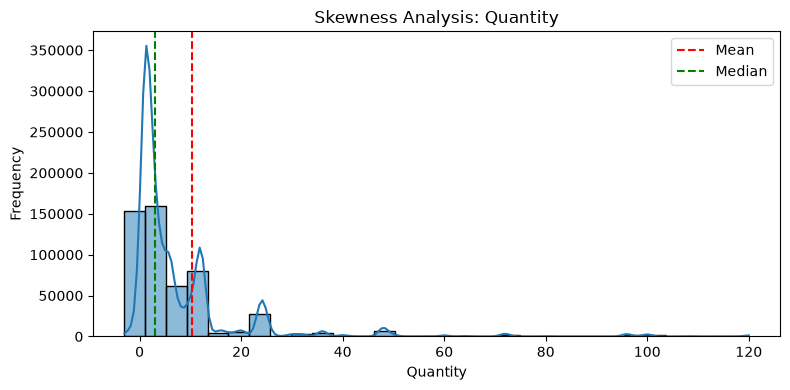


Feature: Price
Valid observations: 525461
Mean: 4.69
Median: 2.10
Skewness: -140.768
Interpretation: Negatively skewed


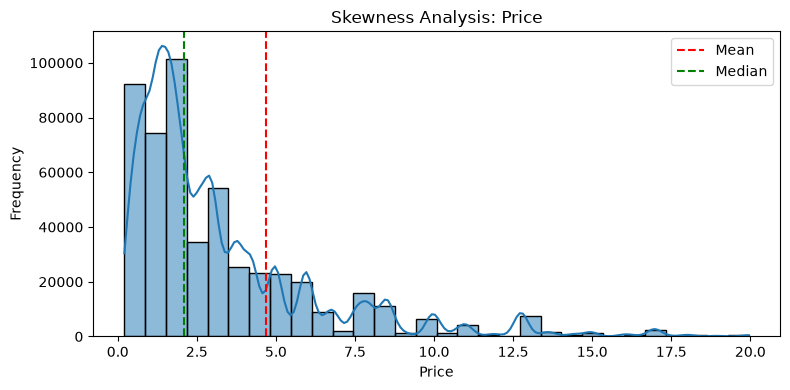

In [7]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical features
features = ["Quantity", "Price"]

distribution_data = df[features].copy()

# Convert columns to numeric
for feature in features:
    distribution_data[feature] = pd.to_numeric(
        distribution_data[feature], errors="coerce"
    )

# Analyze skewness for each feature
for feature in features:
    values = distribution_data[feature].dropna()

    skewness_value = values.skew()
    mean_value = values.mean()
    median_value = values.median()

    if skewness_value > 0.5:
        skew_type = "Positively skewed"
    elif skewness_value < -0.5:
        skew_type = "Negatively skewed"
    else:
        skew_type = "Approximately symmetric by this rule"

    print(f"\nFeature: {feature}")
    print("Valid observations:", len(values))
    print(f"Mean: {mean_value:.2f}")
    print(f"Median: {median_value:.2f}")
    print(f"Skewness: {skewness_value:.3f}")
    print("Interpretation:", skew_type)

    # Limit extreme values for visualization only
    lower = values.quantile(0.01)
    upper = values.quantile(0.99)
    plot_values = values[
        (values >= lower) & (values <= upper)
    ]

    plt.figure(figsize=(8, 4))
    sns.histplot(plot_values, bins=30, kde=True)
    plt.axvline(
        mean_value, color="red", linestyle="--", label="Mean"
    )
    plt.axvline(
        median_value, color="green", linestyle="--", label="Median"
    )
    plt.title(f"Skewness Analysis: {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.legend()
    plt.tight_layout()
    plt.show()


## Step 3: Code Explanation and Analysis

### 1. What the Code Does

- Selects the `Quantity` and `Price` columns.
- Converts the values into numeric format and excludes missing values.
- Calculates the mean, median, and skewness of each feature.
- Classifies skewness using simple thresholds for interpretation.
- Plots a histogram and KDE curve for each feature.
- Displays mean and median reference lines.

### 2. Why These Methods Were Used

- **Pandas:** Prepares the data and calculates skewness.
- **NumPy:** Supports numerical operations.
- **Matplotlib:** Adds graph labels and reference lines.
- **Seaborn:** Displays distribution shapes using histograms and KDE curves.
- **Mean and Median:** Help compare the center of the distribution.
- **Skewness:** Measures distribution asymmetry.

The thresholds of +0.5 and -0.5 are practical interpretation rules used here, not universal statistical boundaries.

### 3. What the Output Means

- **Positive Skewness:** The distribution has a longer right tail.
- **Negative Skewness:** The distribution has a longer left tail.
- **Skewness Near Zero:** The distribution has less measured asymmetry.
- **Mean and Median:** A noticeable difference may support the presence of skewness.
- **Histogram and KDE:** Show the shape and concentration of values.

A distribution with skewness near zero can still have multiple peaks or other departures from normality.

### 4. Insights That Can Be Obtained

After running the code, determine:

- Which feature has stronger skewness.
- Whether the mean and median differ substantially.
- Whether the histogram supports the calculated skewness.
- Whether extreme values may contribute to the observed tail.
- Whether `Quantity` and `Price` show different distribution patterns.

Write your observations from the actual outputs.

### 5. How the Result Can Affect an ML Pipeline

- **Feature Transformation:** Log or other transformations may help with strongly skewed positive features when appropriate.
- **Scaling:** Robust scaling may be useful when extreme values influence the feature.
- **Outlier Investigation:** Skewness may signal a need to investigate unusual observations, but it does not identify outliers by itself.
- **Model Selection:** Some algorithms are more sensitive to feature distributions than others.
- **Model Evaluation:** Transformations must be learned from training data and applied consistently to validation and test data to avoid data leakage.

### Important Note

The percentile filter affects only the displayed histogram. The reported skewness, mean, and median are calculated using all valid observations. The original dataset is not modified.

# Topic 4: Kurtosis

## Step 1: Understand the Concept

Kurtosis is a statistical measure that describes the tail characteristics of a probability distribution.

It helps us understand whether a distribution has relatively heavy or light tails compared with a normal distribution.

### Types of Kurtosis

- **Mesokurtic:** A distribution with kurtosis similar to a normal distribution.
- **Leptokurtic:** A distribution with heavier tails and a greater tendency to produce extreme values.
- **Platykurtic:** A distribution with lighter tails and generally fewer extreme values than a normal distribution.

### Why Is It Important?

Kurtosis helps analysts understand tail behavior, investigate extreme observations, and assess whether unusual values may affect statistical analysis or machine learning.

## Step 2: Demonstrate the Concept

### Simple Example

Imagine two groups of exam marks. One group has marks concentrated near the average, while another group has more extreme low and high marks. Their tail behavior may differ.

### Real-World Example

Financial returns may show heavy tails, meaning very large gains or losses can occur more often than a normal distribution would suggest.

### Business Example

A retail company may investigate whether a small number of transactions have unusually large quantities or prices.

### AI/ML Use Case

Kurtosis can help with exploratory data analysis and identifying features that may contain extreme observations.

### Important Characteristics

- **Excess kurtosis near zero:** Similar tail behavior to a normal distribution under the standard convention.
- **Positive excess kurtosis:** Heavier tails relative to a normal distribution.
- **Negative excess kurtosis:** Lighter tails relative to a normal distribution.
- High kurtosis does not identify which individual records are outliers.


Feature: Quantity
Valid observations: 525461
Mean: 10.34
Median: 3.00
Excess kurtosis: 6277.667
Interpretation: Positive excess kurtosis


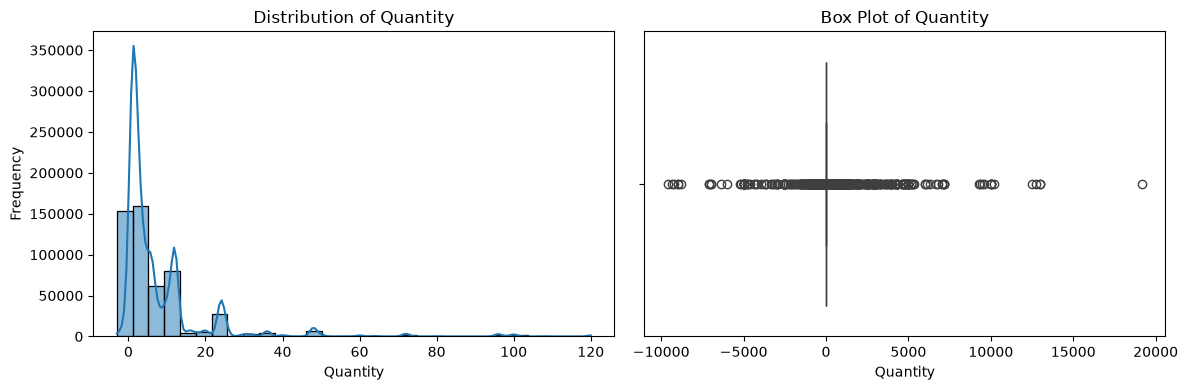


Feature: Price
Valid observations: 525461
Mean: 4.69
Median: 2.10
Excess kurtosis: 64868.345
Interpretation: Positive excess kurtosis


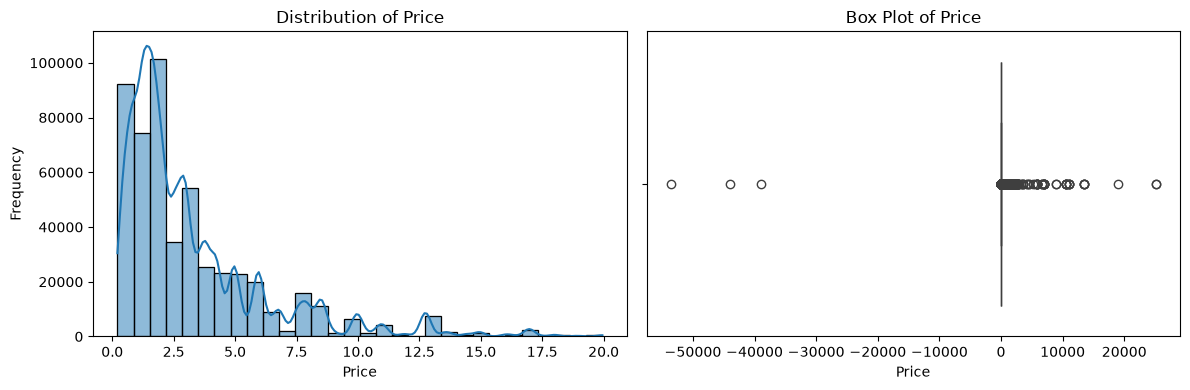

In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical features
features = ["Quantity", "Price"]

distribution_data = df[features].copy()

# Convert columns to numeric
for feature in features:
    distribution_data[feature] = pd.to_numeric(
        distribution_data[feature], errors="coerce"
    )

for feature in features:
    values = distribution_data[feature].dropna()

    kurtosis_value = values.kurt()
    mean_value = values.mean()
    median_value = values.median()

    if kurtosis_value > 0:
        interpretation = "Positive excess kurtosis"
    elif kurtosis_value < 0:
        interpretation = "Negative excess kurtosis"
    else:
        interpretation = "Excess kurtosis approximately zero"

    print(f"\nFeature: {feature}")
    print("Valid observations:", len(values))
    print(f"Mean: {mean_value:.2f}")
    print(f"Median: {median_value:.2f}")
    print(f"Excess kurtosis: {kurtosis_value:.3f}")
    print("Interpretation:", interpretation)

    # Use percentiles for clearer histogram visualization
    lower = values.quantile(0.01)
    upper = values.quantile(0.99)
    plot_values = values[
        (values >= lower) & (values <= upper)
    ]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(plot_values, bins=30, kde=True, ax=axes[0])
    axes[0].set_title(f"Distribution of {feature}")
    axes[0].set_xlabel(feature)
    axes[0].set_ylabel("Frequency")

    sns.boxplot(x=values, ax=axes[1])
    axes[1].set_title(f"Box Plot of {feature}")
    axes[1].set_xlabel(feature)

    plt.tight_layout()
    plt.show()


## Step 3: Code Explanation and Analysis

### 1. What the Code Does

- Selects `Quantity` and `Price` from the dataset.
- Converts the columns into numeric values and excludes missing values.
- Calculates mean, median, and excess kurtosis.
- Displays a histogram with a KDE curve.
- Displays a box plot to help investigate possible outliers.

### 2. Why These Methods Were Used

- **Pandas:** Prepares the data and calculates kurtosis.
- **NumPy:** Supports numerical operations.
- **Matplotlib:** Arranges the plots and displays them.
- **Seaborn:** Creates the histogram, KDE curve, and box plot.
- **Kurtosis:** Describes relative tail behavior.
- **Box Plot:** Helps identify observations beyond the usual IQR-based whisker limits.

Pandas' `.kurt()` reports excess kurtosis, for which a normal distribution has a theoretical value of zero.

### 3. What the Output Means

- **Positive Excess Kurtosis:** Indicates heavier tails relative to a normal distribution under this measure.
- **Negative Excess Kurtosis:** Indicates lighter tails relative to a normal distribution.
- **Histogram:** Shows where values are concentrated.
- **Box Plot:** Points beyond the whiskers are potential outliers that need investigation.

The histogram is limited to the 1st–99th percentile range for visibility, while kurtosis and the box plot use all valid values.

### 4. Insights That Can Be Obtained

After running the code, examine:

- Which feature has higher excess kurtosis.
- Whether extreme observations appear in the box plot.
- Whether the histogram shows a long tail or concentrated values.
- Whether the results suggest that unusual values need further investigation.

Kurtosis is influenced by extreme observations, but a high value does not prove that every extreme observation is an error.

### 5. How the Result Can Affect an ML Pipeline

- **Outlier Investigation:** High kurtosis may encourage closer inspection of extreme values.
- **Preprocessing:** Transformations or robust scaling may be considered if extreme values affect a model.
- **Model Selection:** Some algorithms are more sensitive to extreme observations than others.
- **Data Quality:** Potential data-entry errors should be corrected only after verification.
- **Model Evaluation:** Any transformation or preprocessing rule should be learned from training data and applied consistently to validation and test data.

### Important Note

Do not remove records based only on kurtosis. Investigate whether each unusual value is a genuine observation, a data-entry error, or an unusual but valid transaction.

# Topic 5: Symmetric Distribution

## Step 1: Understand the Concept

A symmetric distribution is a distribution in which the left and right sides have approximately the same shape around the center.

In a perfectly symmetric distribution, values are balanced on both sides of the center.

### Key Characteristics

- Both sides have similar shapes.
- The distribution is balanced around its center.
- In a perfectly symmetric, unimodal distribution, the mean and median are generally equal.
- A symmetric distribution is not necessarily a normal distribution.

### Why Is It Important?

Symmetry helps analysts understand whether values are balanced around the center and whether the data may have noticeable asymmetry.

## Step 2: Demonstrate the Concept

### Simple Example

Consider the values 10, 20, 30, 40, and 50. Their values are balanced around the center value of 30.

### Real-World Example

Some measurement errors may be approximately symmetric around zero when a measurement process is unbiased.

### Business Example

A company may analyze the difference between actual delivery time and target delivery time to check whether delays and early deliveries are balanced.

### AI/ML Use Case

Symmetry analysis can help data scientists understand feature distributions and investigate whether a feature is strongly skewed.

### Important Note

A distribution can be symmetric but still have multiple peaks, heavy tails, or outliers. Symmetry alone does not prove normality.

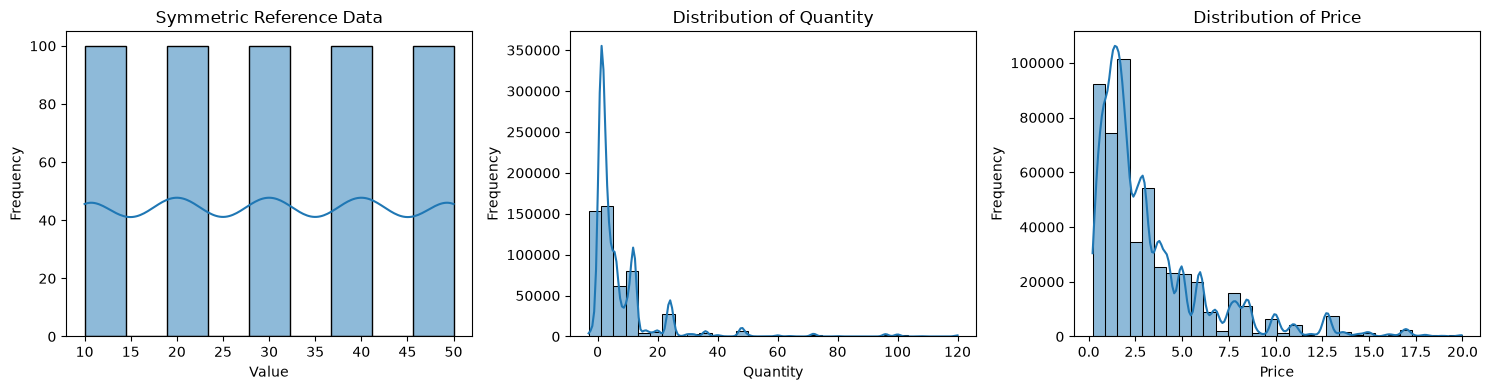


Feature: Quantity
Mean: 10.34
Median: 3.00
Skewness: 36.045

Feature: Price
Mean: 4.69
Median: 2.10
Skewness: -140.768


In [9]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical features
features = ["Quantity", "Price"]
distribution_data = df[features].copy()

# Convert selected columns to numeric
for feature in features:
    distribution_data[feature] = pd.to_numeric(
        distribution_data[feature], errors="coerce"
    )

# Create a simple symmetric reference dataset
symmetric_reference = np.array(
    [10, 20, 30, 40, 50] * 100
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(
    symmetric_reference, bins=9, kde=True, ax=axes[0]
)
axes[0].set_title("Symmetric Reference Data")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Frequency")

for ax, feature in zip(axes[1:], features):
    values = distribution_data[feature].dropna()

    # Limit extreme values for visualization only
    lower = values.quantile(0.01)
    upper = values.quantile(0.99)
    plot_values = values[
        (values >= lower) & (values <= upper)
    ]

    sns.histplot(plot_values, bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# Calculate statistics using all valid observations
for feature in features:
    values = distribution_data[feature].dropna()

    print(f"\nFeature: {feature}")
    print(f"Mean: {values.mean():.2f}")
    print(f"Median: {values.median():.2f}")
    print(f"Skewness: {values.skew():.3f}")


## Step 3: Code Explanation and Analysis

### 1. What the Code Does

- Selects `Quantity` and `Price` from the retail dataset.
- Converts values to numeric format and excludes missing values.
- Creates reference data with values balanced around the center.
- Plots the reference distribution alongside the actual feature distributions.
- Calculates the mean, median, and skewness of each feature.

### 2. Why These Methods Were Used

- **Pandas:** Selects and prepares the dataset columns.
- **NumPy:** Creates the symmetric reference data and supports calculations.
- **Matplotlib:** Arranges the comparison plots.
- **Seaborn:** Displays distribution shapes through histograms and KDE curves.
- **Mean and Median:** Help compare the center of each feature.
- **Skewness:** Measures asymmetry numerically.

The reference dataset is intentionally symmetric. The real retail features must be assessed from their own results.

### 3. What the Output Means

- **Symmetric Reference Plot:** Shows an example of values balanced around the center.
- **Retail Histograms:** Show how `Quantity` and `Price` are distributed.
- **Mean and Median:** Similar values can be consistent with symmetry, but do not prove it.
- **Skewness Near Zero:** Suggests less asymmetry, but does not prove normality.

### 4. Insights That Can Be Obtained

After running the code, identify:

- Whether each retail feature appears balanced around its center.
- Whether the mean and median are close.
- Whether skewness indicates noticeable asymmetry.
- Whether extreme observations may influence the distribution.
- How the real data differs from the symmetric reference.

Write observations based on the actual output.

### 5. How the Result Can Affect an ML Pipeline

- **Preprocessing:** Strong asymmetry may motivate testing suitable transformations.
- **Feature Scaling:** The choice of scaler should depend on the feature and model, not symmetry alone.
- **Outlier Investigation:** A symmetric distribution can still contain extreme values.
- **Model Assumptions:** Symmetry is different from normality; check the exact assumption required by a statistical method.
- **Data Validation:** Compare feature distributions between training and future data to detect changes.

### Important Note

The percentile filter is used only for plotting. Summary statistics use all valid observations. No original records are removed or modified.

# Topic 6: Left-Skewed Distribution

## Step 1: Understand the Concept

A left-skewed distribution is a distribution in which the tail extends farther toward the left side.

It is also called a negatively skewed distribution because its skewness is generally negative.

### Key Characteristics

- The tail extends toward lower values.
- Most observations may be concentrated toward the higher end.
- The mean is often lower than the median.
- The skewness value is generally negative.

### Why Is It Important?

Left-skewed distribution analysis helps identify patterns in numerical data and understand whether a small number of low values may affect the distribution.

## Step 2: Demonstrate the Concept

### Simple Example

Imagine an easy exam in which most students score high marks, but a few students score very low marks. The distribution may have a longer tail toward the lower scores.

### Real-World Example

Customer satisfaction scores may be left-skewed when most customers give high ratings and a small number give very low ratings.

### Business Example

A product may receive mostly high ratings, while a few very low ratings create a left tail in the distribution.

### AI/ML Use Case

Identifying left-skewed features helps data scientists understand data patterns and decide whether transformations or additional investigation may be useful.

### Important Note

A negative skewness value suggests left asymmetry, but the histogram should also be inspected. Not every dataset with negative skewness has a clearly visible left tail.

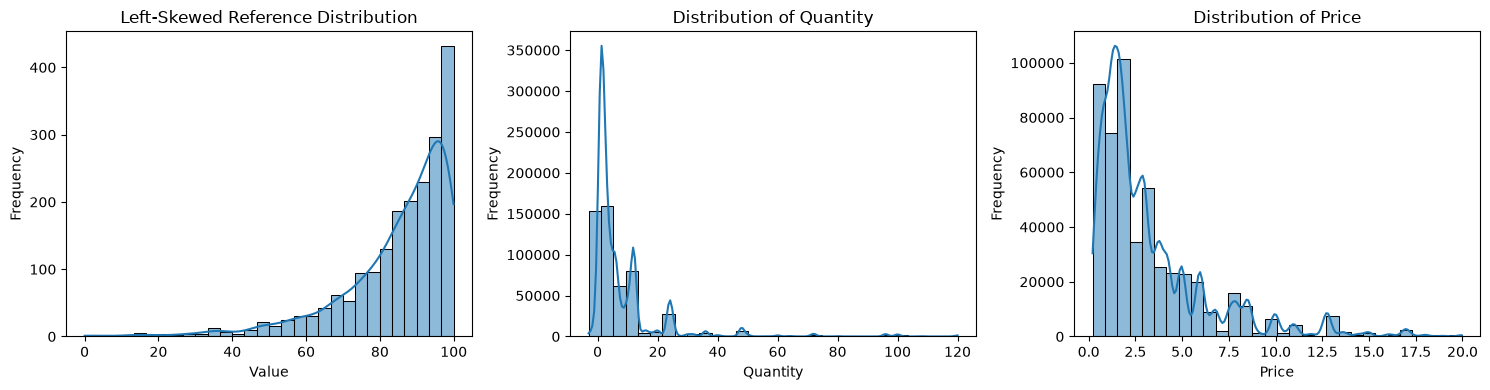


Feature: Quantity
Mean: 10.34
Median: 3.00
Skewness: 36.045

Feature: Price
Mean: 4.69
Median: 2.10
Skewness: -140.768


In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical features
features = ["Quantity", "Price"]
distribution_data = df[features].copy()

# Convert columns to numeric
for feature in features:
    distribution_data[feature] = pd.to_numeric(
        distribution_data[feature], errors="coerce"
    )

# Generate left-skewed reference data
np.random.seed(42)
left_skewed_reference = 100 - np.random.exponential(
    scale=15, size=2000
)
left_skewed_reference = np.clip(
    left_skewed_reference, 0, 100
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(
    left_skewed_reference, bins=30, kde=True, ax=axes[0]
)
axes[0].set_title("Left-Skewed Reference Distribution")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Frequency")

for ax, feature in zip(axes[1:], features):
    values = distribution_data[feature].dropna()

    # Limit extreme values for visualization only
    lower = values.quantile(0.01)
    upper = values.quantile(0.99)
    plot_values = values[
        (values >= lower) & (values <= upper)
    ]

    sns.histplot(plot_values, bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# Calculate statistics using all valid observations
for feature in features:
    values = distribution_data[feature].dropna()

    print(f"\nFeature: {feature}")
    print(f"Mean: {values.mean():.2f}")
    print(f"Median: {values.median():.2f}")
    print(f"Skewness: {values.skew():.3f}")


## Step 3: Code Explanation and Analysis

### 1. What the Code Does

- Selects `Quantity` and `Price` from the retail dataset.
- Converts the selected columns into numeric values and excludes missing values.
- Generates a reference dataset designed to have a left-skewed shape.
- Plots the reference data and the real feature distributions.
- Calculates the mean, median, and skewness for each real feature.

### 2. Why These Methods Were Used

- **Pandas:** Selects and prepares the numerical features.
- **NumPy:** Generates the reference data and supports calculations.
- **Matplotlib:** Arranges the plots for comparison.
- **Seaborn:** Displays the distributions using histograms and KDE curves.
- **Mean and Median:** Help compare the center of the data.
- **Skewness:** Quantifies the direction and degree of asymmetry.

The reference data demonstrates left skewness; it does not imply that the retail features must be left-skewed.

### 3. What the Output Means

- **Left-Skewed Reference Plot:** Most values should be toward the higher end, with a tail extending toward lower values.
- **Mean and Median:** The mean is often below the median in a left-skewed distribution.
- **Negative Skewness:** Indicates asymmetry toward lower values.
- **Retail Histograms:** Show whether the real features have similar patterns.

### 4. Insights That Can Be Obtained

After running the code, examine:

- Whether `Quantity` or `Price` has negative skewness.
- Whether the histogram shows a longer left tail.
- Whether the mean is below the median.
- Whether unusually low values may influence the distribution.
- Whether further investigation of extreme values is necessary.

Write your findings based on the actual output, not the reference data alone.

### 5. How the Result Can Affect an ML Pipeline

- **Feature Transformation:** A suitable transformation may help with some strongly skewed features, depending on the data and algorithm.
- **Outlier Investigation:** Unusually low values should be checked before deciding how to handle them.
- **Feature Scaling:** Robust scaling may help when extreme values affect a model.
- **Model Selection:** Some models are more sensitive to feature distributions than others.
- **Data Leakage Prevention:** Fit transformations on training data only, then apply them to validation and test data.

### Important Note

The percentile filter is used only for visual clarity. The reported statistics use all valid observations, and the original dataset is not modified.

# Topic 7: Right-Skewed Distribution

## Step 1: Understand the Concept

A right-skewed distribution is a distribution in which the tail extends farther toward the right side.

It is also called a positively skewed distribution because its skewness is generally positive.

### Key Characteristics

- The tail extends toward higher values.
- Many observations may be concentrated at the lower end.
- The mean is often greater than the median.
- The skewness value is generally positive.

### Why Is It Important?

Right-skewed distribution analysis helps identify features with a small number of very large values and understand how those values affect statistical summaries and machine learning.

## Step 2: Demonstrate the Concept

### Simple Example

Imagine monthly salaries in a company. Many employees may earn moderate salaries, while a few executives earn much higher salaries. The distribution may have a long right tail.

### Real-World Example

House prices may be right-skewed when most houses are moderately priced but a few luxury properties are extremely expensive.

### Business Example

In retail, many products may have low or moderate prices, while a few products have very high prices.

### AI/ML Use Case

Right-skewness analysis helps data scientists identify features that may need additional investigation or a suitable transformation before model training.

### Important Note

Positive skewness suggests right asymmetry, but it does not automatically mean the data contains errors or that outliers should be removed.

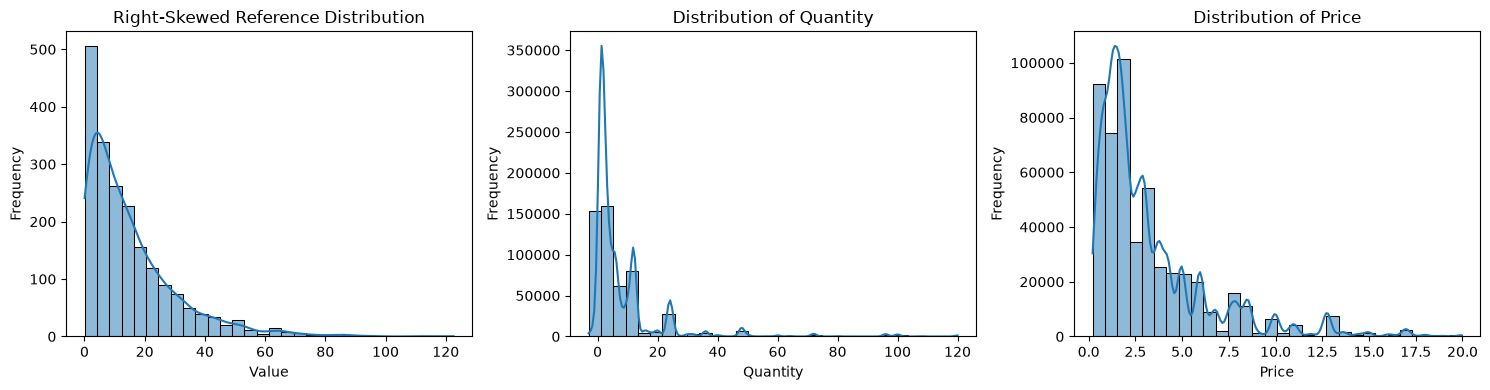


Feature: Quantity
Mean: 10.34
Median: 3.00
Skewness: 36.045

Feature: Price
Mean: 4.69
Median: 2.10
Skewness: -140.768


In [11]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical features
features = ["Quantity", "Price"]
distribution_data = df[features].copy()

# Convert columns to numeric
for feature in features:
    distribution_data[feature] = pd.to_numeric(
        distribution_data[feature], errors="coerce"
    )

# Generate right-skewed reference data
np.random.seed(42)
right_skewed_reference = np.random.exponential(
    scale=15, size=2000
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(
    right_skewed_reference, bins=30, kde=True, ax=axes[0]
)
axes[0].set_title("Right-Skewed Reference Distribution")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Frequency")

for ax, feature in zip(axes[1:], features):
    values = distribution_data[feature].dropna()

    # Limit extreme values for visualization only
    lower = values.quantile(0.01)
    upper = values.quantile(0.99)
    plot_values = values[
        (values >= lower) & (values <= upper)
    ]

    sns.histplot(plot_values, bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# Calculate statistics using all valid observations
for feature in features:
    values = distribution_data[feature].dropna()

    print(f"\nFeature: {feature}")
    print(f"Mean: {values.mean():.2f}")
    print(f"Median: {values.median():.2f}")
    print(f"Skewness: {values.skew():.3f}")


## Step 3: Code Explanation and Analysis

### 1. What the Code Does

- Selects `Quantity` and `Price` from the retail dataset.
- Converts values to numeric format and excludes missing values.
- Generates a reference dataset with a right-skewed distribution.
- Plots the reference data alongside the real feature distributions.
- Calculates the mean, median, and skewness of each feature.

### 2. Why These Methods Were Used

- **Pandas:** Selects columns and prepares the data.
- **NumPy:** Generates reference values and supports numerical operations.
- **Matplotlib:** Arranges the plots and displays them.
- **Seaborn:** Creates histograms and KDE curves.
- **Mean and Median:** Help compare the center of the data.
- **Skewness:** Measures the direction and degree of asymmetry.

The reference data demonstrates right skewness; the retail features must be interpreted from their own results.

### 3. What the Output Means

- **Right-Skewed Reference Plot:** Most values are near the lower end, with a tail extending toward higher values.
- **Positive Skewness:** Indicates asymmetry toward higher values.
- **Mean and Median:** The mean is often greater than the median in a right-skewed distribution.
- **Retail Histograms:** Show whether the real features have similar patterns.

### 4. Insights That Can Be Obtained

After running the code, examine:

- Whether `Quantity` or `Price` has positive skewness.
- Whether the histogram has a longer right tail.
- Whether the mean is greater than the median.
- Whether a few large values may influence the distribution.
- Whether those values need further investigation.

Record your observations based on the actual output.

### 5. How the Result Can Affect an ML Pipeline

- **Feature Transformation:** A log or other suitable transformation may help with strongly right-skewed positive features.
- **Outlier Investigation:** Large values should be checked to determine whether they are valid or erroneous.
- **Feature Scaling:** Robust scaling may help some models when extreme values influence training.
- **Model Selection:** Distribution patterns can affect the performance of algorithms that are sensitive to feature scales or assumptions.
- **Data Leakage Prevention:** Fit transformations using training data only, then apply the same transformation to validation and test data.

### Important Note

The percentile filter is used only for visualization. The statistics use all valid observations, and the original dataset is not modified.

# Final Distribution Analysis

## Objective

Analyze the important numerical features using the following measures:

- Shape of distribution
- Center
- Spread
- Skewness
- Possible outliers

This analysis helps understand the distribution patterns of `Quantity` and `Price` in the Online Retail dataset.


Feature: Quantity
Valid observations: 525461
Distribution shape: Right-skewed
Mean (center): 10.338
Median (center): 3.000
Standard deviation (spread): 107.424
Minimum: -9600.000
Maximum: 19152.000
Q1: 1.000
Q3: 10.000
IQR: 9.000
Skewness: 36.045
Potential outlier count (IQR rule): 57870


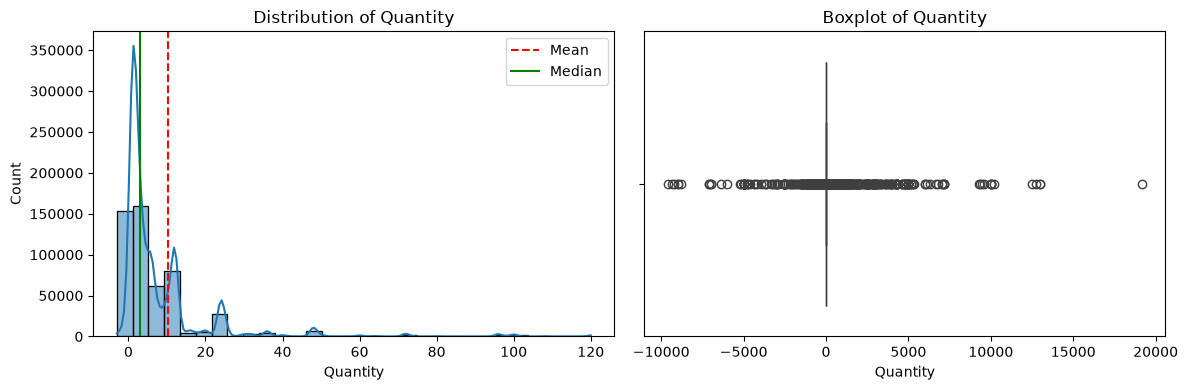


Feature: Price
Valid observations: 525461
Distribution shape: Left-skewed
Mean (center): 4.689
Median (center): 2.100
Standard deviation (spread): 146.127
Minimum: -53594.360
Maximum: 25111.090
Q1: 1.250
Q3: 4.210
IQR: 2.960
Skewness: -140.768
Potential outlier count (IQR rule): 35273


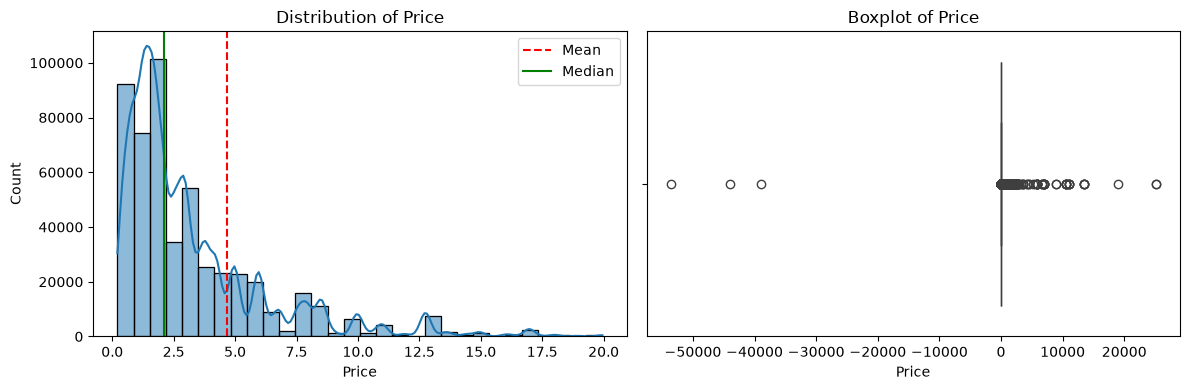

In [12]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

features = ["Quantity", "Price"]

for feature in features:
    values = pd.to_numeric(df[feature], errors="coerce").dropna()

    if values.empty:
        print(f"No valid numerical values found for {feature}.")
        continue

    mean_value = values.mean()
    median_value = values.median()
    std_value = values.std()
    minimum = values.min()
    maximum = values.max()
    skew_value = values.skew()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    outlier_count = (
        (values < lower_fence) | (values > upper_fence)
    ).sum()

    if skew_value > 0.5:
        shape = "Right-skewed"
    elif skew_value < -0.5:
        shape = "Left-skewed"
    else:
        shape = "Approximately symmetric by skewness"

    print(f"\n{'=' * 40}")
    print(f"Feature: {feature}")
    print(f"{'=' * 40}")
    print(f"Valid observations: {len(values)}")
    print(f"Distribution shape: {shape}")
    print(f"Mean (center): {mean_value:.3f}")
    print(f"Median (center): {median_value:.3f}")
    print(f"Standard deviation (spread): {std_value:.3f}")
    print(f"Minimum: {minimum:.3f}")
    print(f"Maximum: {maximum:.3f}")
    print(f"Q1: {q1:.3f}")
    print(f"Q3: {q3:.3f}")
    print(f"IQR: {iqr:.3f}")
    print(f"Skewness: {skew_value:.3f}")
    print(f"Potential outlier count (IQR rule): {outlier_count}")

    # Plot the distribution
    lower = values.quantile(0.01)
    upper = values.quantile(0.99)
    plot_values = values[
        (values >= lower) & (values <= upper)
    ]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(plot_values, bins=30, kde=True, ax=axes[0])
    axes[0].axvline(
        mean_value, color="red", linestyle="--", label="Mean"
    )
    axes[0].axvline(
        median_value, color="green", linestyle="-", label="Median"
    )
    axes[0].set_title(f"Distribution of {feature}")
    axes[0].legend()

    sns.boxplot(x=values, ax=axes[1])
    axes[1].set_title(f"Boxplot of {feature}")

    plt.tight_layout()
    plt.show()


## Explanation and Interpretation

### 1. Shape of Distribution

The histogram shows how numerical values are distributed.

- A longer right tail may indicate right skewness.
- A longer left tail may indicate left skewness.
- A balanced shape may indicate approximate symmetry.

The skewness value helps support this interpretation, but the histogram should also be examined.

### 2. Center

- **Mean:** The average value.
- **Median:** The middle value after sorting the observations.

A large difference between the mean and median may indicate skewness or extreme observations.

### 3. Spread

- **Standard Deviation:** Measures how much values vary around the mean.
- **IQR:** Measures the spread of the middle 50% of observations.
- **Minimum and Maximum:** Show the full observed range.

### 4. Skewness

- Positive skewness indicates a tendency toward a longer right tail.
- Negative skewness indicates a tendency toward a longer left tail.
- Skewness near zero indicates less asymmetry, but does not prove that the distribution is normal.

### 5. Possible Outliers

The IQR rule identifies values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR as potential outliers.

These values need investigation. They are not necessarily incorrect and should not automatically be removed.

### 6. Machine Learning Relevance

Distribution analysis can help determine whether to investigate extreme values, transform highly skewed features, or use robust scaling. Any preprocessing decisions should be based on the dataset, the business context, and the model being developed.

### Conclusion

The final results summarize the shape, center, spread, skewness, and potential outliers of `Quantity` and `Price`. Use the actual numerical output and plots to record your findings rather than assuming that both features follow a particular distribution.